# Handwritten math to LaTeX: Qwen3-VL before vs after fine-tuning · 手寫數學算式轉 LaTeX：Qwen3-VL 微調前後對照

Fine-tune the vision-language model **Qwen3-VL-4B-Instruct** with QLoRA so it turns **images of
handwritten math** into LaTeX that matches the dataset's annotation style (no `$$`, no spaces
between symbols, `\begin{matrix}` for matrices, and so on).

Steps:
1. Load the dataset [`deepcopy/MathWriting-human`](https://huggingface.co/datasets/deepcopy/MathWriting-human)
2. Fine-tune with 4-bit quantization + LoRA (TRL `SFTTrainer`)
3. Compare exact match and character error rate (CER) before and after fine-tuning on **test data
   not seen during training**
4. Show 3 examples that were wrong before and right after fine-tuning

---

用 QLoRA 微調視覺語言模型 **Qwen3-VL-4B-Instruct**，讓它把**手寫數學算式圖片**轉成符合資料集標註風格的
LaTeX（不加 `$$`、不在符號間插空格、矩陣用 `\begin{matrix}` 等）。

流程：
1. 載入資料集 [`deepcopy/MathWriting-human`](https://huggingface.co/datasets/deepcopy/MathWriting-human)
2. 用 4-bit 量化 + LoRA 微調（TRL `SFTTrainer`）
3. 在**訓練時沒看過的 test 資料**上，比較微調前後的 exact match 與字元錯誤率（CER）
4. 挑出「微調前答錯、微調後答對」的 3 個例子並排展示

## 0. Install packages · 0. 安裝套件

In [1]:
%pip install -q transformers trl peft bitsandbytes accelerate datasets pillow


/workspace/playground/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## 1. Settings · 1. 設定

In [2]:
from pathlib import Path

import torch

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
DATASET_NAME = "deepcopy/MathWriting-human"
TRAIN_FILE = "data/train-00000-of-00003-ab0ae6b9fa4a3f06.parquet"
TEST_FILE = "data/test-00000-of-00001-694f317d8b634199.parquet"
PROMPT_TEXT = "Transcribe the handwritten math expression in this image into LaTeX."

OUTPUT_DIR = str(Path.cwd() / "outputs" / "Qwen3-VL-4B-Instruct-MathWriting-SFT")

MAX_STEPS = 400          # 2 x 8 = 16 rows per step; 400 steps see about 6400 rows (~1 epoch), ~20 min on an H100 / 每步 2 × 8 = 16 筆，400 步約看過 6400 筆（約 1 個 epoch），H100 約 20 分鐘
TRAIN_LIMIT = 6400       # number of training rows, must be >= MAX_STEPS x 16 / 訓練資料筆數，需 >= MAX_STEPS × 16
NUM_EVAL = 100           # number of test rows to evaluate / 用來評估的 test 筆數
NUM_SHOWCASE = 3         # number of examples to showcase / 最後展示幾個例子


## 2. Prepare the data · 2. 準備資料

Each example is an image of a handwritten expression (`image`) and its LaTeX (`latex`), converted
into TRL's `images` / `prompt` / `completion` format.

---

每筆資料是一張手寫算式圖片（`image`）與對應的 LaTeX（`latex`），轉成 TRL 的
`images` / `prompt` / `completion` 格式。

/workspace/playground/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 6400 筆, test: 100 筆
LaTeX: V(\tilde{\beta})


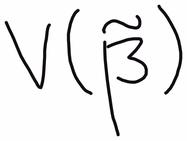

In [3]:
from datasets import load_dataset


def to_vlm_format(example):
    return {
        "images": [example["image"].convert("RGB")],
        "prompt": [{"role": "user", "content": PROMPT_TEXT}],
        "completion": [{"role": "assistant", "content": example["latex"]}],
    }


def load_split(data_file, limit):
    dataset = load_dataset(
        DATASET_NAME, data_files={"train": data_file}, split="train", verification_mode="no_checks"
    )
    dataset = dataset.select(range(min(limit, len(dataset))))
    return dataset.map(to_vlm_format, remove_columns=dataset.column_names)


train_dataset = load_split(TRAIN_FILE, TRAIN_LIMIT)
eval_dataset = load_split(TEST_FILE, NUM_EVAL)

print(f"train: {len(train_dataset)} rows, test: {len(eval_dataset)} rows")
example = train_dataset[0]
print("LaTeX:", example["completion"][0]["content"])
example["images"][0]


## 3. Load the model (4-bit) and build the LoRA trainer · 3. 載入模型（4-bit 量化）並建立 LoRA 訓練器

In [4]:
from peft import LoraConfig
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration
from trl import SFTConfig, SFTTrainer
from trl.trainer.sft_trainer import DataCollatorForVisionLanguageModeling

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    dtype="float32",
    device_map="auto",
    quantization_config=BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        bnb_4bit_quant_type="nf4",
    ),
)
processor = AutoProcessor.from_pretrained(MODEL_ID)

peft_config = LoraConfig(
    r=32,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)

training_args = SFTConfig(
    output_dir=OUTPUT_DIR,
    max_steps=MAX_STEPS,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    warmup_steps=5,
    learning_rate=2e-4,
    optim="adamw_8bit",
    max_length=None,  # no truncation, so image tokens are not cut / 不截斷，避免切掉圖片 token
    logging_steps=10,
    report_to="none",
    push_to_hub=False,
)

# recompute mm_token_type_ids from input_ids so they stay aligned after batch padding / 依 input_ids 重新計算 mm_token_type_ids，確保 batch padding 後仍與 input_ids 對齊
base_collator = DataCollatorForVisionLanguageModeling(processor)


def collate(examples):
    batch = base_collator(examples)
    ids = batch["input_ids"]
    mm_token_type_ids = (ids == processor.image_token_id).long()
    mm_token_type_ids[ids == processor.video_token_id] = 2
    batch["mm_token_type_ids"] = mm_token_type_ids
    return batch


trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    peft_config=peft_config,
    data_collator=collate,
)


W0929 10:18:23.027000 2293 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W0929 10:18:23.051000 2293 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 713/713 [00:06<00:00, 105.07it/s]


## 4. Train · 4. 訓練

In [5]:
trainer_stats = trainer.train()

train_runtime = trainer_stats.metrics["train_runtime"]
vram_peak_gb = torch.cuda.max_memory_reserved() / 1024**3 if torch.cuda.is_available() else 0.0
print(f"Fine-tuning time: {train_runtime:.1f} s (~{train_runtime / 60:.1f} min)")
print(f"Peak VRAM (reserved): {vram_peak_gb:.2f} GB")


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
/workspace/playground/.venv/lib/python3.13/site-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/workspace/playground/.venv/lib/python3.13/site-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args

Step,Training Loss
10,13.770700
20,6.281179
30,5.618959
40,5.406963
50,5.361485
60,5.336634
70,5.386787
80,5.340173
90,5.212221
100,5.323248


微調耗時：1068.7 秒（約 17.8 分鐘）
VRAM 峰值（reserved）：5.38 GB


## 5. Save the LoRA adapter · 5. 儲存 LoRA adapter

In [6]:
trainer.save_model(OUTPUT_DIR)
print(f"Adapter saved to {OUTPUT_DIR}")


adapter 已存到 /workspace/playground/notebook-demo/outputs/Qwen3-VL-4B-Instruct-MathWriting-SFT


## 6. Evaluate before and after fine-tuning · 6. 微調前後評估

Free the 4-bit training model, reload the original model (before fine-tuning) to generate LaTeX
for the test data, then apply the LoRA adapter we just trained (after fine-tuning) and generate
again for **the same images and prompt**.

Before comparing, `$` and all whitespace are stripped (the original model tends to add `$$` and
spaces between symbols, which is not a recognition error):
- **exact match**: share of normalized outputs identical to the reference (higher is better)
- **CER**: character error rate = total edit distance / total reference length (lower is better)

---

釋放訓練用的 4-bit 模型，重新載入原始模型（微調前）對 test 資料生成 LaTeX，再套上剛訓練好的 LoRA adapter
（微調後）對**同樣的圖片與 prompt** 各生成一次。

比對前先去掉 `$` 與所有空白（原始模型習慣加 `$$` 與符號間空格，這不算辨識錯誤）：
- **exact match**：正規化後與標準答案完全一致的比例（越高越好）
- **CER**：字元錯誤率 = 編輯距離總和 / 標準答案總長度（越低越好）

In [7]:
import gc

from peft import PeftModel

del trainer, model
gc.collect()
torch.cuda.empty_cache()

# some torchao versions are incompatible with peft; skip peft's torchao detection before loading the adapter / 部分環境的 torchao 版本與 peft 不相容，載入 adapter 前略過 peft 對 torchao 的偵測
try:
    import peft.tuners.lora.torchao as peft_torchao

    peft_torchao.is_torchao_available = lambda: False
except ImportError:
    pass

base_model = Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID, dtype="float32", device_map="auto")


def generate_reply(model, image, max_new_tokens=128):
    messages = [{"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": PROMPT_TEXT}]}]
    inputs = processor.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    generated_ids = model.generate(**inputs, max_new_tokens=max_new_tokens)
    trimmed = [out[len(inp):] for inp, out in zip(inputs.input_ids, generated_ids)]
    return processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]


def normalize_latex(text):
    return "".join(text.replace("$", "").split())


def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        cur = [i]
        for j, cb in enumerate(b, start=1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def score(replies, references):
    dists = [edit_distance(normalize_latex(r), normalize_latex(ref)) for r, ref in zip(replies, references)]
    total_len = sum(max(len(normalize_latex(ref)), 1) for ref in references)
    return {"dists": dists, "exact_match": sum(d == 0 for d in dists) / len(dists), "cer": sum(dists) / total_len}


images = [ex["images"][0] for ex in eval_dataset]
references = [ex["completion"][0]["content"] for ex in eval_dataset]

base_replies = [generate_reply(base_model, image) for image in images]
base_score = score(base_replies, references)

fine_tuned_model = PeftModel.from_pretrained(base_model, OUTPUT_DIR)
ft_replies = [generate_reply(fine_tuned_model, image) for image in images]
ft_score = score(ft_replies, references)

print(f"Evaluation data: {len(images)} test rows")
print(f"Before  exact match = {base_score['exact_match']:.1%}, CER = {base_score['cer']:.1%}")
print(f"After   exact match = {ft_score['exact_match']:.1%}, CER = {ft_score['cer']:.1%}")


Loading weights: 100%|██████████| 713/713 [00:02<00:00, 295.16it/s]


評估資料：test 100 筆
微調前  exact match = 21.0%, CER = 43.3%
微調後  exact match = 31.0%, CER = 26.4%


## 7. Showcase: wrong before, right after fine-tuning · 7. 展示：微調前答錯、微調後答對的例子

微調前答錯、微調後完全答對：17 / 100 筆


/workspace/playground/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 31684 (\N{CJK UNIFIED IDEOGRAPH-7BC4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/workspace/playground/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20363 (\N{CJK UNIFIED IDEOGRAPH-4F8B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


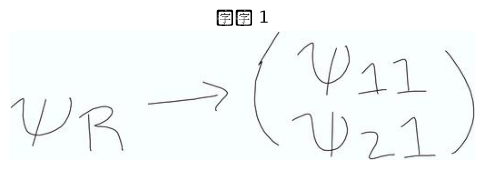

標準答案 : \psi_{R}\rightarrow(\begin{matrix}\psi_{11}\\ \psi_{21}\end{matrix})
微調前   : $$\psi _ { R } \rightarrow \left( \begin{array} { c } { { \psi _ { 1 1 } } } \\ { { \psi _ { 2 1 } } } \end{array} \right)$$
微調後   : \psi_{R}\rightarrow(\begin{matrix}\psi_{11}\\\psi_{21}\end{matrix})



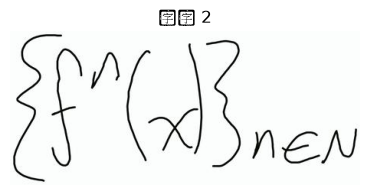

標準答案 : \{f^{n}(x)\}_{n\in N}
微調前   : $$\mathcal { E } f ^ { n } ( x ) \mathcal { B } _ { n \in \mathbb { N } }$$
微調後   : \{f^{n}(x)\}_{n\in N}



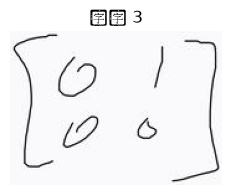

標準答案 : [\begin{matrix}0&1\\ 0&0\end{matrix}]
微調前   : $$\left[ \begin{array}{c} 0 \\ 0 \end{array} \right]$$
微調後   : [\begin{matrix}0&1\\ 0&0\end{matrix}]



In [8]:
import matplotlib.pyplot as plt

flipped = [i for i in range(len(images)) if base_score["dists"][i] > 0 and ft_score["dists"][i] == 0]
flipped.sort(key=lambda i: base_score["dists"][i], reverse=True)  # worst-before first / 微調前錯得越離譜越優先
print(f"Wrong before, exactly right after: {len(flipped)} / {len(images)} rows")

for rank, i in enumerate(flipped[:NUM_SHOWCASE], start=1):
    plt.figure(figsize=(6, 2))
    plt.imshow(images[i])
    plt.axis("off")
    plt.title(f"Example {rank}")
    plt.show()
    print(f"Reference: {references[i]}")
    print(f"Before   : {base_replies[i]}")
    print(f"After    : {ft_replies[i]}")
    print()


## 8. Summary · 8. 總結

In [9]:
print(f"Training data: {len(train_dataset)} rows, {MAX_STEPS} steps")
print(f"Fine-tuning time: {train_runtime:.1f} s (~{train_runtime / 60:.1f} min), peak VRAM ~{vram_peak_gb:.1f} GB")
print()
print(f"{'':8s}{'exact match':>14s}{'CER':>10s}")
print(f"{'Before':8s}{base_score['exact_match']:>14.1%}{base_score['cer']:>10.1%}")
print(f"{'After':8s}{ft_score['exact_match']:>14.1%}{ft_score['cer']:>10.1%}")


訓練資料：6400 筆，400 步
微調耗時：1068.7 秒（約 17.8 分鐘），VRAM 峰值約 5.4 GB

           exact match       CER
微調前              21.0%     43.3%
微調後              31.0%     26.4%
